Freeform GPT Features — EDA + XGBoost

1. Load & inspect freeform feature CSV
2. Sanity checks vs RDKit ground truth (side-by-side grid)
3. Cross-correlation heatmap: RDKit vs freeform GPT
4. Build feature matrix
5. XGBoost — exact same pipeline as `build_train.py`

**Only change the config cell when switching models.**

In [63]:
from IPython.display import display
import warnings, random
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    f1_score, precision_score, recall_score, accuracy_score, matthews_corrcoef
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb

def find_data_dir():
    here = Path().resolve()
    for candidate in [here / "data", here.parent / "data"]:
        if (candidate / "prestwick_library_screened.tsv.gz").exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/ from {here}")

DATA_DIR   = find_data_dir()
RDKIT_PATH = DATA_DIR / "maier_chemdesc_representation.tsv"
PAIRS_FILE = DATA_DIR / "results" / "mole_plus_gpt41mini" / "compound_strain_pairs_with_features_mole_plus_gpt.csv"

# ── Change these two lines to switch models ────────────────────────────────────
FREEFORM_CSV = DATA_DIR / "gpt_generation_without_guidance" / "gpt_features5_gpt-5.2_freeform.csv"
MODEL_TAG    = "gpt-5.2-freeform"

OUT_DIR = DATA_DIR / "feature_matrix_gpt" / "freeform" / MODEL_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Freeform CSV : {FREEFORM_CSV}")
print(f"Output dir   : {OUT_DIR}")

Freeform CSV : D:\Hiwi\GPT+Mole\GPT+Mole\data\gpt_generation_without_guidance\gpt_features5_gpt-5.2_freeform.csv
Output dir   : D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_matrix_gpt\freeform\gpt-5.2-freeform


## 1. Load & Inspect

In [64]:
raw = pd.read_csv(FREEFORM_CSV)
META_COLS    = {"prestwick_ID", "smiles_resolution", "input"}
feature_cols = [c for c in raw.columns if c not in META_COLS]

print(f"Shape        : {raw.shape}")
print(f"Feature cols : {feature_cols}")
raw.head(3)

Shape        : (1197, 221)
Feature cols : ['atom_count_total', 'atom_count_heavy', 'atom_count_hydrogen', 'element_count_c', 'element_count_n', 'element_count_o', 'element_count_s', 'element_count_p', 'element_count_f', 'element_count_cl', 'element_count_br', 'element_count_i', 'element_count_b', 'element_count_si', 'element_count_se', 'element_count_metal', 'molecular_weight', 'exact_mass_est', 'average_atomic_number', 'valence_electron_count', 'formal_charge_total', 'formal_charge_positive', 'formal_charge_negative', 'radical_electron_count', 'bond_count_total', 'bond_count_single', 'bond_count_double', 'bond_count_aromatic', 'bond_count_triple', 'bond_count_amide', 'bond_count_urea', 'bond_count_imide', 'bond_count_carbonyl', 'bond_count_n_o', 'bond_count_n_n', 'bond_count_c_n', 'bond_count_c_o', 'bond_count_c_c', 'ring_count_total', 'ring_count_aromatic', 'ring_count_aliphatic', 'ring_count_fused', 'ring_count_spiro', 'ring_count_bridgehead', 'largest_ring_size', 'smallest_ring_siz

,atom_count_total,atom_count_heavy,atom_count_hydrogen,element_count_c,element_count_n,element_count_o,element_count_s,element_count_p,element_count_f,element_count_cl,...,lead_like_score_est,drug_like_score_est,antimicrobial_like_score_est,antimetabolite_like_score_est,nucleobase_antimetabolite_potential_est,transport_via_nucleobase_transporters_score_est,prodrug_feasibility_score_est,input,prestwick_ID,smiles_resolution
0,11,10,1,2,7,1,0,0,0,0,...,0.85,0.55,0.25,0.65,0.60,0.40,0.35,"{'query_smiles': 'Nc1nc2n[nH]nc2c(=O)[nH]1', '...",Prestw-1,fast
1,17,11,6,6,4,2,1,0,0,0,...,0.55,0.60,0.55,0.15,0.05,0.05,0.25,{'query_smiles': 'NC(N)=NS(=O)(=O)c1ccc(N)cc1'...,Prestw-10,fast
2,25,18,7,11,2,3,1,0,0,0,...,0.65,0.70,0.45,0.20,0.15,0.10,0.25,{'query_smiles': 'COC(=O)Nc1nc2ccc(C(=O)c3cccs...,Prestw-100,fast


In [65]:
print(pd.DataFrame({"dtype": raw[feature_cols].dtypes,
                     "nulls": raw[feature_cols].isnull().sum()}))
raw[feature_cols].describe().round(3)

                                                   dtype  nulls
atom_count_total                                   int64      0
atom_count_heavy                                   int64      0
atom_count_hydrogen                                int64      0
element_count_c                                    int64      0
element_count_n                                    int64      0
...                                                  ...    ...
antimicrobial_like_score_est                     float64      0
antimetabolite_like_score_est                    float64      0
nucleobase_antimetabolite_potential_est          float64      0
transport_via_nucleobase_transporters_score_est  float64      0
prodrug_feasibility_score_est                    float64      0

[218 rows x 2 columns]


,atom_count_total,atom_count_heavy,atom_count_hydrogen,element_count_c,element_count_n,element_count_o,element_count_s,element_count_p,element_count_f,element_count_cl,...,desolvation_penalty_est,binding_site_hbonding_advantage_est,fragment_like_score_est,lead_like_score_est,drug_like_score_est,antimicrobial_like_score_est,antimetabolite_like_score_est,nucleobase_antimetabolite_potential_est,transport_via_nucleobase_transporters_score_est,prodrug_feasibility_score_est
count,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,...,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.00,1197.000,1197.000,1197.000
mean,35.292,21.568,13.723,14.222,2.158,3.466,0.272,0.017,0.165,0.212,...,0.532,0.436,0.421,0.485,0.598,0.363,0.12,0.097,0.067,0.266
std,20.713,11.454,10.290,7.228,1.850,4.291,0.582,0.157,0.646,0.574,...,0.137,0.205,0.235,0.212,0.169,0.123,0.19,0.201,0.136,0.065
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000
25%,24.000,15.000,8.000,9.000,1.000,1.000,0.000,0.000,0.000,0.000,...,0.450,0.250,0.250,0.350,0.550,0.250,0.00,0.000,0.000,0.250
50%,29.000,19.000,11.000,13.000,2.000,2.000,0.000,0.000,0.000,0.000,...,0.550,0.450,0.350,0.550,0.650,0.350,0.05,0.000,0.000,0.250
75%,43.000,25.000,16.000,18.000,3.000,4.000,0.000,0.000,0.000,0.000,...,0.600,0.600,0.550,0.650,0.700,0.450,0.15,0.100,0.050,0.350
max,247.000,113.000,134.000,58.000,15.000,36.000,4.000,2.000,7.000,5.000,...,0.950,0.900,0.950,0.850,0.800,0.850,0.90,0.950,0.750,0.550




In [66]:
n, ncols = len(feature_cols), 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    axes[i].hist(raw[col].dropna(), bins=40, color="#185FA5", alpha=0.75, edgecolor="none")
    axes[i].set_title(col, fontsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
fig.suptitle(f"Feature Distributions — {MODEL_TAG}", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Sanity Checks vs RDKit (Side-by-Side)

In [67]:
rdkit = pd.read_csv(RDKIT_PATH, sep="\t")

# GPT feature name -> closest RDKit column
SANITY_MAP = {
    "molecular_weight":               "MolWt",
    "num_hydrogen_bond_donors":       "NumHDonors",
    "num_hydrogen_bond_acceptors":    "NumHAcceptors",
    "num_aromatic_rings":             "NumAromaticRings",
    "num_rings":                      "NumRings",
    "topological_polar_surface_area": "TPSA",
    "fraction_csp3":                  "FractionCSP3",
    "num_rotatable_bonds":            "NumRotatableBonds",
}

valid_pairs = [(g, r) for g, r in SANITY_MAP.items()
               if g in raw.columns and r in rdkit.columns]
print(f"Sanity check pairs: {len(valid_pairs)}")
for g, r in valid_pairs:
    print(f"  {g:42s} -> {r}")

Sanity check pairs: 3
  molecular_weight                           -> MolWt
  topological_polar_surface_area             -> TPSA
  fraction_csp3                              -> FractionCSP3


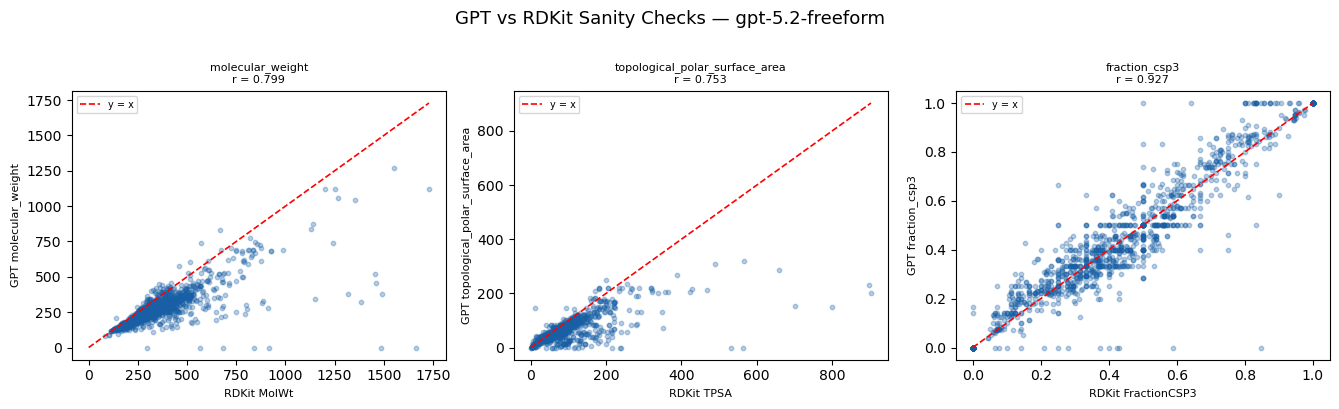

5 MOST SIMILAR (GPT ≈ RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-1202,153.137,153.137,-0.0
1,Prestw-1203,130.078,130.080,0.0
2,Prestw-1207,180.159,180.158,-0.0
3,Prestw-1268,124.139,124.139,0.0
4,Prestw-1310,308.381,308.380,-0.0



5 MOST OVERESTIMATED (GPT >> RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-837,568.751,741.00,172.25
1,Prestw-1036,666.910,834.06,167.15
2,Prestw-388,456.678,574.80,118.12
3,Prestw-148,357.470,449.56,92.09
4,Prestw-384,516.857,602.95,86.09



5 MOST UNDERESTIMATED (GPT << RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-522,1664.922,0.00,-1664.92
1,Prestw-497,1485.732,0.00,-1485.73
2,Prestw-160,1488.807,381.43,-1107.38
3,Prestw-506,1385.461,323.35,-1062.11
4,Prestw-159,1461.429,453.41,-1008.02


In [68]:
merged = raw[["prestwick_ID"] + [g for g, _ in valid_pairs]].merge(
    rdkit[["prestwick_ID"] + [r for _, r in valid_pairs]], on="prestwick_ID", how="inner"
)

n_pairs = len(valid_pairs)
ncols   = min(4, n_pairs)
nrows   = (n_pairs + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 4))
axes = np.array(axes).flatten()

sanity_results = []
for i, (gpt_col, rdkit_col) in enumerate(valid_pairs):
    ax   = axes[i]
    x, y = merged[rdkit_col], merged[gpt_col]
    r, p  = spearmanr(x, y)
    sanity_results.append({"gpt": gpt_col, "rdkit": rdkit_col,
                            "spearman_r": round(r, 4), "p": round(p, 6)})
    ax.scatter(x, y, alpha=0.3, s=10, color="#185FA5", rasterized=True)
    mn, mx = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=1.2, label="y = x")
    ax.set_xlabel(f"RDKit {rdkit_col}", fontsize=8)
    ax.set_ylabel(f"GPT {gpt_col}", fontsize=8)
    ax.set_title(f"{gpt_col}\nr = {r:.3f}", fontsize=8)
    ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"GPT vs RDKit Sanity Checks — {MODEL_TAG}", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "sanity_checks.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Molecular weight deep-dive table ──────────────────────────────────────────
mw_gpt_col   = "molecular_weight"
mw_rdkit_col = "MolWt"

if mw_gpt_col in merged.columns and mw_rdkit_col in merged.columns:
    mw = merged[["prestwick_ID", mw_rdkit_col, mw_gpt_col]].copy()
    mw = mw.rename(columns={mw_rdkit_col: "rdkit_MolWt", mw_gpt_col: "gpt_MolWt"})
    mw["diff"]     = (mw["gpt_MolWt"] - mw["rdkit_MolWt"]).round(2)
    mw["abs_diff"] = mw["diff"].abs()

    closest   = mw.nsmallest(5, "abs_diff").reset_index(drop=True)
    overest   = mw.nlargest(5,  "diff").reset_index(drop=True)
    underest  = mw.nsmallest(5, "diff").reset_index(drop=True)

    print("5 MOST SIMILAR (GPT ≈ RDKit):")
    display(closest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST OVERESTIMATED (GPT >> RDKit):")
    display(overest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST UNDERESTIMATED (GPT << RDKit):")
    display(underest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

# ── MAE and Median Absolute Error ─────────────────────────────────────────────
print("\n=== Numerical Accuracy (MAE / MedAE) ===")
acc_rows = []
for g, r in valid_pairs:
    x = merged[r].values.astype(float)
    y = merged[g].values.astype(float)
    mask = np.isfinite(x) & np.isfinite(y)
    mae   = float(np.mean(np.abs(y[mask] - x[mask])))
    medae = float(np.median(np.abs(y[mask] - x[mask])))
    acc_rows.append({"gpt_feature": g, "rdkit_feature": r,
                     "MAE": round(mae, 3), "MedAE": round(medae, 3)})
    print(f"  {g:42s} vs {r:22s}: MAE={mae:8.3f}  MedAE={medae:8.3f}")

acc_df = pd.DataFrame(acc_rows)
display(acc_df)


## 3. Cross-Correlation: RDKit vs Freeform GPT

RDKit: 96 features  |  GPT freeform: 215 features


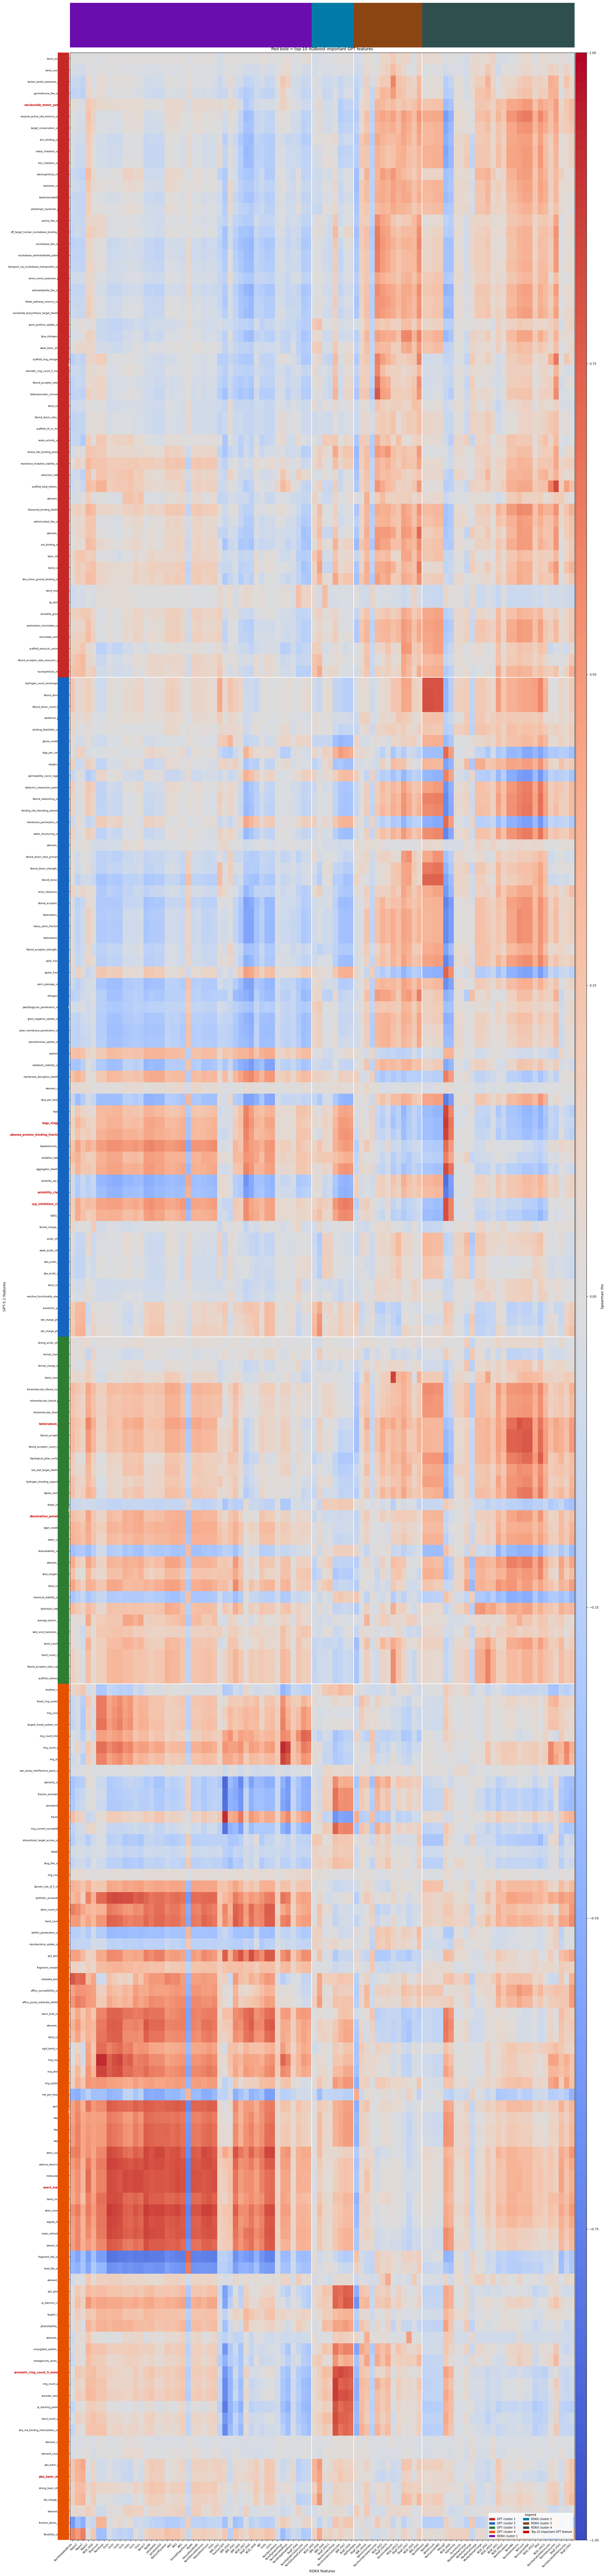

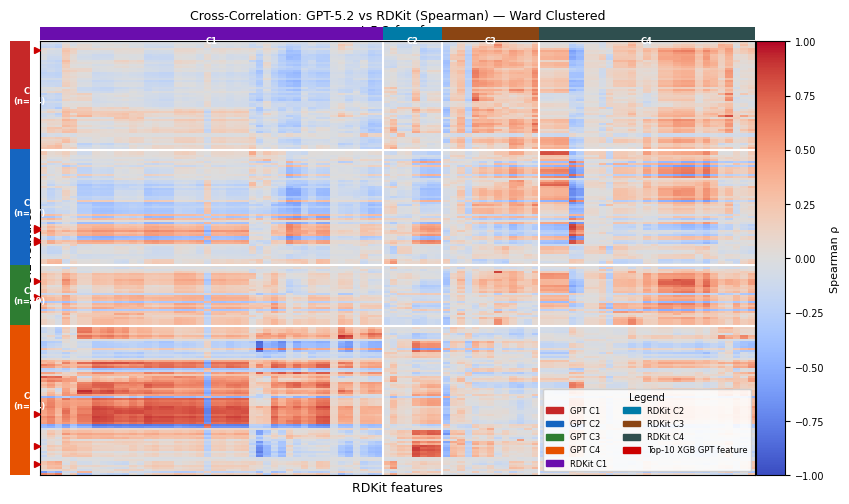

In [69]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from matplotlib.colors import ListedColormap, BoundaryNorm

rdkit_al = (rdkit.set_index("prestwick_ID")
                .apply(pd.to_numeric, errors="coerce").fillna(0))
rdkit_al = rdkit_al.loc[:, rdkit_al.std() > 1e-6]

gpt_al = (raw.set_index("prestwick_ID")[feature_cols]
             .apply(pd.to_numeric, errors="coerce").fillna(0))
gpt_al = gpt_al.loc[:, gpt_al.std() > 1e-6]

common   = rdkit_al.index.intersection(gpt_al.index)
rdkit_al = rdkit_al.loc[common].sort_index()
gpt_al   = gpt_al.loc[common].sort_index()

rdkit_al.columns = ["rdkit__" + c for c in rdkit_al.columns]
gpt_al.columns   = ["gpt__"   + c for c in gpt_al.columns]

n_rdkit, n_gpt = rdkit_al.shape[1], gpt_al.shape[1]
print(f"RDKit: {n_rdkit} features  |  GPT freeform: {n_gpt} features")

combined_all = pd.concat([rdkit_al, gpt_al], axis=1)
full_corr    = combined_all.corr(method="spearman")
corr_sp      = full_corr

rdkit_cols_idx = [c for c in full_corr.columns if c.startswith("rdkit__")]
gpt_cols_idx   = [c for c in full_corr.columns if c.startswith("gpt__")]
cross_block    = full_corr.loc[gpt_cols_idx, rdkit_cols_idx]
cross_block.index   = [c.replace("gpt__",   "") for c in cross_block.index]
cross_block.columns = [c.replace("rdkit__", "") for c in cross_block.columns]

# Top-10 important GPT features (freeform_gpt52)
TOP_IMP = {
    "heteroatom_count",
    "desolvation_penalty_est",
    "cyp_inhibition_risk_est",
    "solubility_class_est",
    "pka_basic_min_est",
    "exact_mass_est",
    "aromatic_ring_count_6_membered",
    "nucleoside_mimic_potential",
    "plasma_protein_binding_fraction_est",
    "logp_xlogp3_est",
}

# --- Cluster GPT rows (Ward on cross-correlation profile) ---
def _ward_order(mat):
    d = 1.0 - np.abs(mat)
    d = (d + d.T) / 2
    np.fill_diagonal(d, 0.0)
    d = np.clip(d, 0.0, None)
    Z = linkage(squareform(d), method="ward")
    return leaves_list(Z)

gpt_corr_sq  = cross_block.values @ cross_block.values.T   # GPT x GPT similarity proxy
rdkit_corr_sq = cross_block.values.T @ cross_block.values  # RDKit x RDKit similarity proxy

# normalise to [-1,1] for Ward distance
def _norm_sq(M):
    d = np.diag(M)
    denom = np.sqrt(np.outer(np.clip(d, 1e-12, None), np.clip(d, 1e-12, None)))
    return M / denom

gpt_ord   = _ward_order(_norm_sq(gpt_corr_sq))
rdkit_ord = _ward_order(_norm_sq(rdkit_corr_sq))

cross_ord  = cross_block.values[np.ix_(gpt_ord, rdkit_ord)]
gpt_feat   = [cross_block.index[i]   for i in gpt_ord]
rdkit_feat = [cross_block.columns[i] for i in rdkit_ord]

N_GPT_CL   = 4
N_RDKIT_CL = 4
PAL_GPT   = ["#C62828", "#1565C0", "#2E7D32", "#E65100"]
PAL_RDKIT = ["#6A0DAD", "#007BA7", "#8B4513", "#2F4F4F"]

def _fcluster_from_order(mat_sq, order, n_cl):
    from scipy.cluster.hierarchy import fcluster
    d = 1.0 - np.abs(_norm_sq(mat_sq))
    d = (d + d.T) / 2
    np.fill_diagonal(d, 0.0)
    d = np.clip(d, 0.0, None)
    Z = linkage(squareform(d), method="ward")
    cl = fcluster(Z, t=n_cl, criterion="maxclust")
    return cl[order]

gpt_cl_ord   = _fcluster_from_order(gpt_corr_sq,   gpt_ord,   N_GPT_CL)
rdkit_cl_ord = _fcluster_from_order(rdkit_corr_sq, rdkit_ord, N_RDKIT_CL)

gpt_bounds   = (np.where(np.diff(gpt_cl_ord)   != 0)[0] + 0.5).tolist()
rdkit_bounds = (np.where(np.diff(rdkit_cl_ord) != 0)[0] + 0.5).tolist()

n_gpt_f, n_rdkit_f = len(gpt_feat), len(rdkit_feat)

fig = plt.figure(figsize=(max(24, n_rdkit_f * 0.22), max(6, n_gpt_f * 0.55)))
gs  = fig.add_gridspec(3, 3,
        width_ratios=[0.022, 1.0, 0.022],
        height_ratios=[0.018, 1.0, 0.018],
        hspace=0.006, wspace=0.006)

ax_heat  = fig.add_subplot(gs[1, 1])
ax_left  = fig.add_subplot(gs[1, 0], sharey=ax_heat)   # GPT cluster strip
ax_top   = fig.add_subplot(gs[0, 1], sharex=ax_heat)   # RDKit cluster strip
ax_cbar  = fig.add_subplot(gs[1, 2])

im = ax_heat.imshow(cross_ord, cmap="coolwarm", vmin=-1, vmax=1,
                    aspect="auto", interpolation="nearest", rasterized=True)

for b in gpt_bounds:
    ax_heat.axhline(b, color="white", lw=1.6)
for b in rdkit_bounds:
    ax_heat.axvline(b, color="white", lw=1.6)

# x-axis: RDKit features
ax_heat.set_xticks(range(n_rdkit_f))
ax_heat.set_yticks(range(n_gpt_f))
xlbls = ax_heat.set_xticklabels(rdkit_feat, rotation=45, ha="right", fontsize=6)
ylbls = ax_heat.set_yticklabels(gpt_feat, fontsize=6)

for lbl in list(ylbls):
    if lbl.get_text() in TOP_IMP:
        lbl.set_color("#CC0000")
        lbl.set_fontweight("bold")
        lbl.set_fontsize(7)

ax_heat.set_xlabel("RDKit features", fontsize=9)
ax_heat.set_ylabel("GPT-5.2 features", fontsize=9)
ax_heat.set_title(
    f"Cross-Correlation: GPT-5.2 vs RDKit (Spearman) — Ward Clustered — {MODEL_TAG}\n"
    "Red bold = top-10 XGBoost important GPT features",
    fontsize=10, pad=6)

# GPT cluster strip (left)
cmap_gpt  = ListedColormap(PAL_GPT)
norm_gpt  = BoundaryNorm(np.arange(0.5, N_GPT_CL + 1.5), N_GPT_CL)
ax_left.imshow(gpt_cl_ord.reshape(-1, 1), cmap=cmap_gpt, norm=norm_gpt,
               aspect="auto", interpolation="nearest")
ax_left.set_axis_off()
for k in range(1, N_GPT_CL + 1):
    idxs = np.where(gpt_cl_ord == k)[0]
    if len(idxs):
        ax_left.text(0.5, float(idxs.mean()), str(k),
                     ha="center", va="center", fontsize=8, fontweight="bold",
                     color="white", transform=ax_left.transData)

# RDKit cluster strip (top)
cmap_rdkit = ListedColormap(PAL_RDKIT)
norm_rdkit = BoundaryNorm(np.arange(0.5, N_RDKIT_CL + 1.5), N_RDKIT_CL)
ax_top.imshow(rdkit_cl_ord.reshape(1, -1), cmap=cmap_rdkit, norm=norm_rdkit,
              aspect="auto", interpolation="nearest")
ax_top.set_axis_off()

cbar = fig.colorbar(im, cax=ax_cbar)
cbar.set_label("Spearman rho", fontsize=9)
cbar.ax.tick_params(labelsize=8)

gpt_handles   = [mpatches.Patch(color=PAL_GPT[k],   label=f"GPT cluster {k+1}")
                 for k in range(N_GPT_CL)]
rdkit_handles = [mpatches.Patch(color=PAL_RDKIT[k], label=f"RDKit cluster {k+1}")
                 for k in range(N_RDKIT_CL)]
imp_handle    = mpatches.Patch(color="#CC0000", label="Top-10 important GPT feature")
ax_heat.legend(handles=gpt_handles + rdkit_handles + [imp_handle],
               loc="lower right", fontsize=7, framealpha=0.85,
               title="Legend", title_fontsize=8, ncol=2)

plt.savefig(OUT_DIR / "cross_corr_gpt_vs_rdkit_clustered.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Compact publication figure (no tick labels) ───────────────────────────────
fig_c = plt.figure(figsize=(10, 6))
gs_c  = fig_c.add_gridspec(3, 3,
         width_ratios=[0.04, 1.0, 0.04],
         height_ratios=[0.03, 1.0, 0.03],
         hspace=0.006, wspace=0.006)

ax_c_heat = fig_c.add_subplot(gs_c[1, 1])
ax_c_left = fig_c.add_subplot(gs_c[1, 0], sharey=ax_c_heat)
ax_c_top  = fig_c.add_subplot(gs_c[0, 1], sharex=ax_c_heat)
ax_c_cbar = fig_c.add_subplot(gs_c[1, 2])

im_c = ax_c_heat.imshow(cross_ord, cmap="coolwarm", vmin=-1, vmax=1,
                         aspect="auto", interpolation="nearest", rasterized=True)
for b in gpt_bounds:
    ax_c_heat.axhline(b, color="white", lw=1.5)
for b in rdkit_bounds:
    ax_c_heat.axvline(b, color="white", lw=1.5)

ax_c_heat.set_xticks([])
ax_c_heat.set_yticks([])
ax_c_heat.set_xlabel("RDKit features", fontsize=9)
ax_c_heat.set_ylabel("GPT-5.2 features", fontsize=9)
ax_c_heat.set_title(
    f"Cross-Correlation: GPT-5.2 vs RDKit (Spearman) — Ward Clustered\n{MODEL_TAG}",
    fontsize=9, pad=5)

ax_c_top.imshow(rdkit_cl_ord.reshape(1, -1), cmap=cmap_rdkit, norm=norm_rdkit,
                aspect="auto", interpolation="nearest")
ax_c_top.set_axis_off()

ax_c_left.imshow(gpt_cl_ord.reshape(-1, 1), cmap=cmap_gpt, norm=norm_gpt,
                 aspect="auto", interpolation="nearest")
ax_c_left.set_axis_off()

# GPT cluster badges
for k in range(1, N_GPT_CL + 1):
    idxs = np.where(gpt_cl_ord == k)[0]
    if len(idxs) == 0:
        continue
    mid = float(idxs.mean())
    ax_c_left.text(0.5, mid, f"C{k}\n(n={len(idxs)})",
                   ha="center", va="center", fontsize=6, fontweight="bold",
                   color="white", transform=ax_c_left.transData, linespacing=1.2)

# Red triangle markers for top-10 GPT important features
for pos, name in enumerate(gpt_feat):
    if name in TOP_IMP:
        ax_c_left.plot(0.92, pos, marker=">", color="#CC0000", markersize=4,
                       transform=ax_c_left.transData, clip_on=False)

# RDKit cluster badges on top
for k in range(1, N_RDKIT_CL + 1):
    idxs = np.where(rdkit_cl_ord == k)[0]
    if len(idxs) == 0:
        continue
    ax_c_top.text(float(idxs.mean()), 0.5, f"C{k}",
                  ha="center", va="center", fontsize=6, fontweight="bold",
                  color="white", transform=ax_c_top.transData)

cbar_c = fig_c.colorbar(im_c, cax=ax_c_cbar)
cbar_c.set_label("Spearman \u03c1", fontsize=8)
cbar_c.ax.tick_params(labelsize=7)

gpt_h   = [mpatches.Patch(color=PAL_GPT[k],   label=f"GPT C{k+1}")   for k in range(N_GPT_CL)]
rdkit_h = [mpatches.Patch(color=PAL_RDKIT[k], label=f"RDKit C{k+1}") for k in range(N_RDKIT_CL)]
imp_h   = mpatches.Patch(color="#CC0000", label="Top-10 XGB GPT feature")
ax_c_heat.legend(handles=gpt_h + rdkit_h + [imp_h], loc="lower right",
                 fontsize=6, framealpha=0.85, ncol=2,
                 title="Legend", title_fontsize=7)

plt.savefig(OUT_DIR / "cross_corr_gpt_vs_rdkit_clustered_compact.png", dpi=300, bbox_inches="tight")
plt.show()


Found 10/10 top features in cross_block


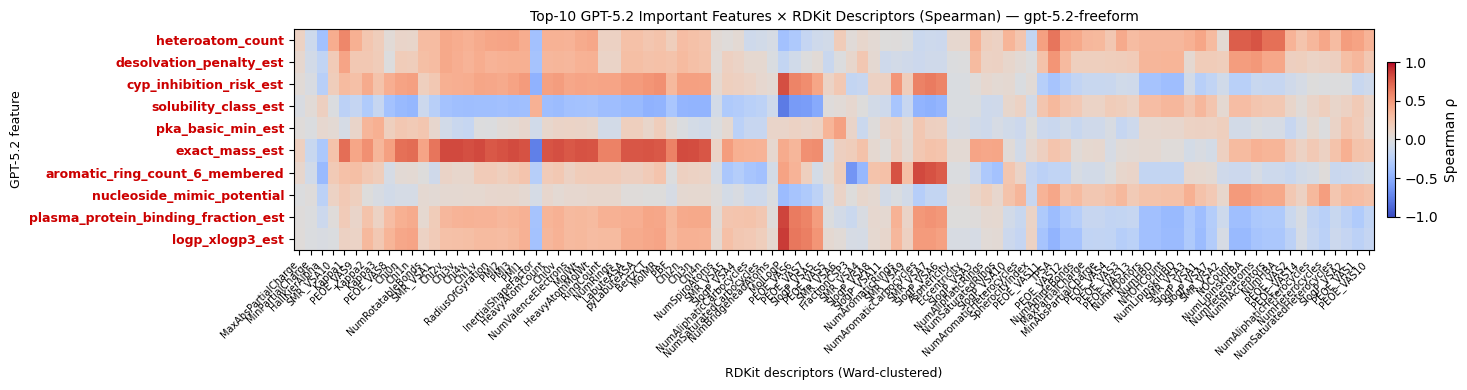

In [70]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

# Top-10 important GPT-5.2 features (from data/results/freeform_gpt52/top_gpt_features_mole_plus_gpt.csv)
TOP_IMP_LIST = [
    "heteroatom_count", "desolvation_penalty_est", "cyp_inhibition_risk_est",
    "solubility_class_est", "pka_basic_min_est", "exact_mass_est",
    "aromatic_ring_count_6_membered", "nucleoside_mimic_potential",
    "plasma_protein_binding_fraction_est", "logp_xlogp3_est",
]

# cross_block has bare GPT names as index, bare RDKit names as columns
# (built in c-crosscorr)
top_rows = [f for f in TOP_IMP_LIST if f in cross_block.index]
print(f"Found {len(top_rows)}/{len(TOP_IMP_LIST)} top features in cross_block")

sub = cross_block.loc[top_rows].copy()   # 10 x n_rdkit

# Ward-cluster RDKit columns by their correlation profile across the 10 rows
rdkit_mat = sub.values.T  # n_rdkit x 10
rdkit_gram = rdkit_mat @ rdkit_mat.T
d = np.diag(rdkit_gram)
denom = np.sqrt(np.outer(np.clip(d, 1e-12, None), np.clip(d, 1e-12, None)))
rdkit_sim = rdkit_gram / denom
rdkit_dist = np.clip(1.0 - np.abs(rdkit_sim), 0, None)
rdkit_dist = (rdkit_dist + rdkit_dist.T) / 2
np.fill_diagonal(rdkit_dist, 0.0)

Z_r   = linkage(squareform(rdkit_dist), method="ward")
r_ord = leaves_list(Z_r)

sub_ord        = sub.values[:, r_ord]
rdkit_feat_ord = [sub.columns[i] for i in r_ord]

fig, ax = plt.subplots(figsize=(16, 4))
im = ax.imshow(sub_ord, cmap="coolwarm", vmin=-1, vmax=1,
               aspect="auto", interpolation="nearest")

ax.set_yticks(range(len(top_rows)))
ylbls = ax.set_yticklabels(top_rows, fontsize=9, fontweight="bold")
for lbl in ylbls:
    lbl.set_color("#CC0000")

ax.set_xticks(range(len(rdkit_feat_ord)))
ax.set_xticklabels(rdkit_feat_ord, rotation=45, ha="right", fontsize=7)

ax.set_title(
    f"Top-10 GPT-5.2 Important Features × RDKit Descriptors (Spearman) — {MODEL_TAG}",
    fontsize=10)
ax.set_xlabel("RDKit descriptors (Ward-clustered)", fontsize=9)
ax.set_ylabel("GPT-5.2 feature", fontsize=9)

fig.colorbar(im, ax=ax, label="Spearman \u03c1", shrink=0.7, pad=0.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "top10_gpt_vs_rdkit_corr.png", dpi=300, bbox_inches="tight")
plt.show()


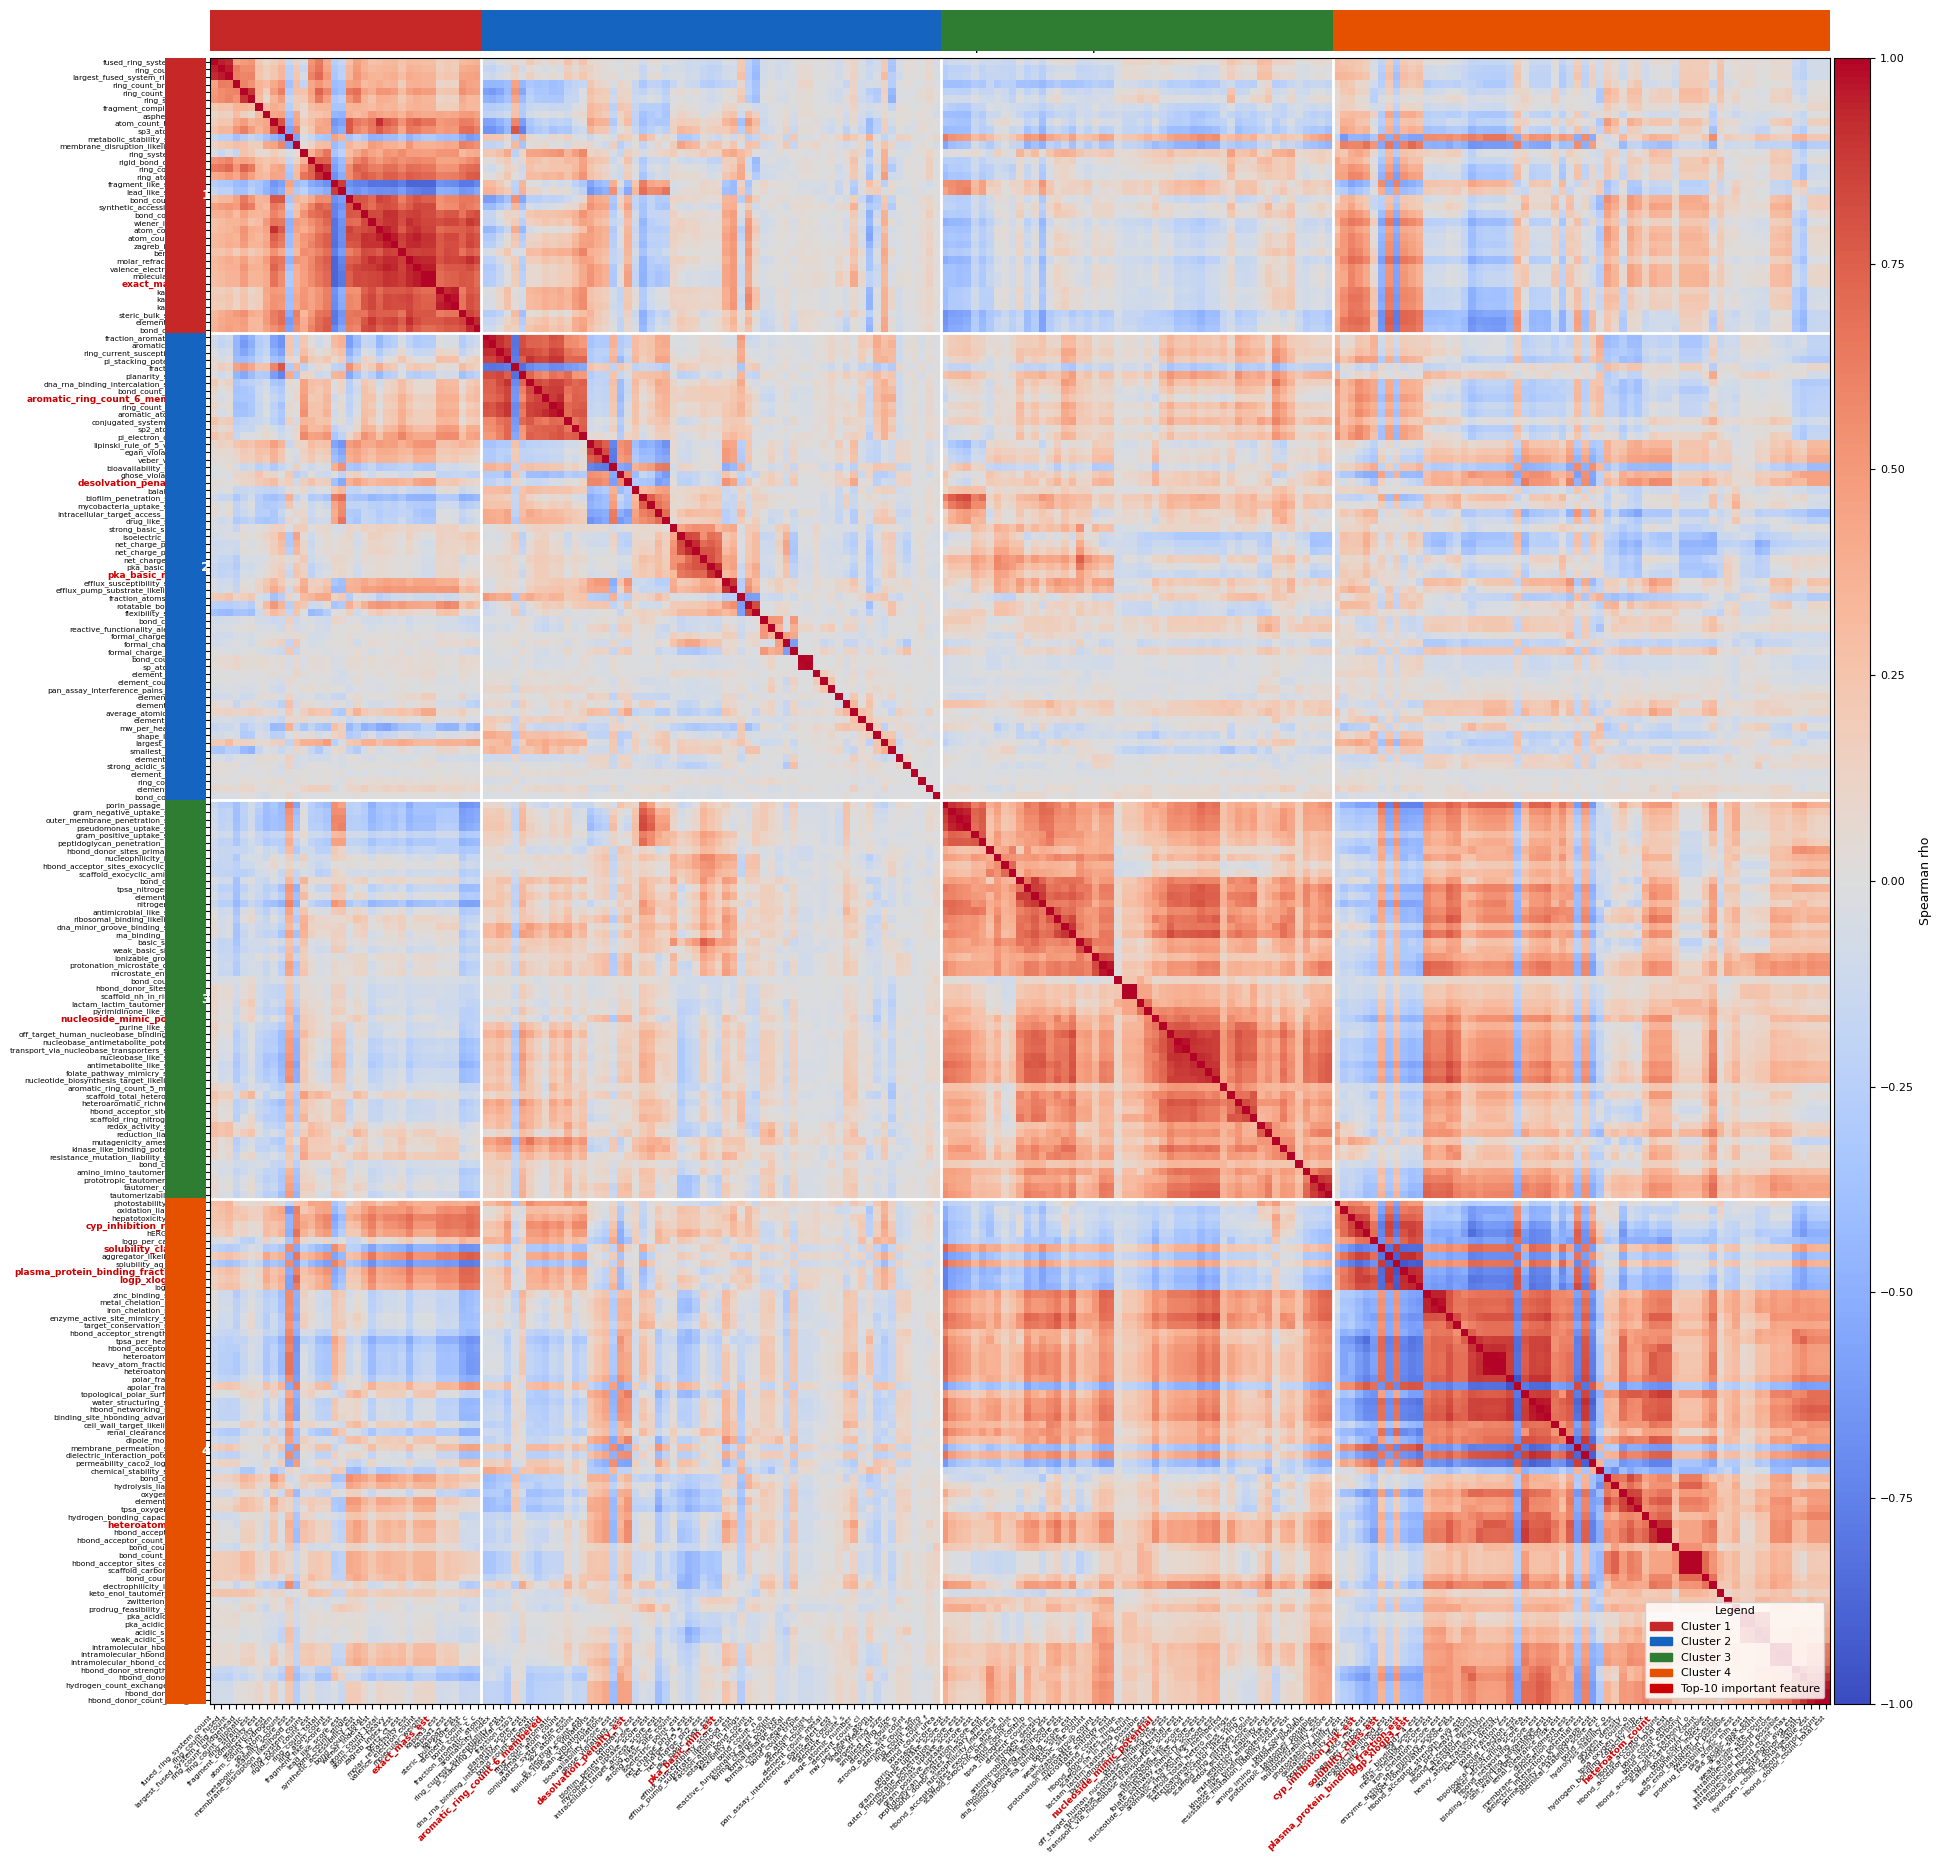

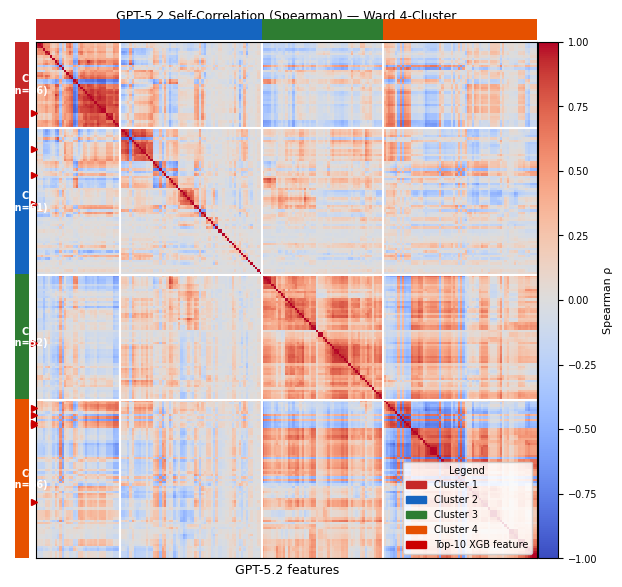

In [71]:
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list
from scipy.spatial.distance import squareform
from matplotlib.colors import ListedColormap, BoundaryNorm

corr_self  = gpt_al.corr(method="spearman")
gpt_labels = [c.replace("gpt__", "") for c in gpt_al.columns]

# Top-10 important features (from data/results/freeform_gpt52/top_gpt_features_mole_plus_gpt.csv)
TOP_IMP = {
    "heteroatom_count",
    "desolvation_penalty_est",
    "cyp_inhibition_risk_est",
    "solubility_class_est",
    "pka_basic_min_est",
    "exact_mass_est",
    "aromatic_ring_count_6_membered",
    "nucleoside_mimic_potential",
    "plasma_protein_binding_fraction_est",
    "logp_xlogp3_est",
}

N_CLUSTERS = 4
PALETTE    = ["#C62828", "#1565C0", "#2E7D32", "#E65100"]

# Ward clustering on 1 - |rho| distance
dist = 1.0 - np.abs(corr_self.values)
dist = (dist + dist.T) / 2
np.fill_diagonal(dist, 0.0)
dist = np.clip(dist, 0.0, None)

Z          = linkage(squareform(dist), method="ward")
leaf_order = leaves_list(Z)
cl_ids     = fcluster(Z, t=N_CLUSTERS, criterion="maxclust")

feat_ord = [gpt_labels[i] for i in leaf_order]
corr_ord = corr_self.values[np.ix_(leaf_order, leaf_order)]
cl_ord   = cl_ids[leaf_order]
n_f      = len(feat_ord)

bounds = (np.where(np.diff(cl_ord) != 0)[0] + 0.5).tolist()

fig = plt.figure(figsize=(22, 22))
gs  = fig.add_gridspec(2, 3,
        width_ratios=[0.025, 1.0, 0.022],
        height_ratios=[0.025, 1.0],
        hspace=0.008, wspace=0.008)

ax_heat = fig.add_subplot(gs[1, 1])
ax_top  = fig.add_subplot(gs[0, 1], sharex=ax_heat)
ax_left = fig.add_subplot(gs[1, 0], sharey=ax_heat)
ax_cbar = fig.add_subplot(gs[1, 2])

im = ax_heat.imshow(corr_ord, cmap="coolwarm", vmin=-1, vmax=1,
                    aspect="auto", interpolation="nearest", rasterized=True)

for b in bounds:
    ax_heat.axhline(b, color="white", lw=2.0)
    ax_heat.axvline(b, color="white", lw=2.0)

ax_heat.set_xticks(range(n_f))
ax_heat.set_yticks(range(n_f))

# Red + bold for top-10 important features; default grey otherwise
xlbls = ax_heat.set_xticklabels(feat_ord, rotation=45, ha="right", fontsize=5.5)
ylbls = ax_heat.set_yticklabels(feat_ord, fontsize=5.5)
for lbl in list(xlbls) + list(ylbls):
    if lbl.get_text() in TOP_IMP:
        lbl.set_color("#CC0000")
        lbl.set_fontweight("bold")
        lbl.set_fontsize(6.5)

ax_heat.set_title(
    f"GPT-5.2 Self-Correlation (Spearman) — Ward 4-Cluster — {MODEL_TAG}\n"
    "Red bold labels = top-10 XGBoost important features",
    fontsize=10, pad=6)

cmap_cl = ListedColormap(PALETTE)
norm_cl = BoundaryNorm(np.arange(0.5, N_CLUSTERS + 1.5), N_CLUSTERS)

ax_top.imshow(cl_ord.reshape(1, -1), cmap=cmap_cl, norm=norm_cl,
              aspect="auto", interpolation="nearest")
ax_top.set_axis_off()

ax_left.imshow(cl_ord.reshape(-1, 1), cmap=cmap_cl, norm=norm_cl,
               aspect="auto", interpolation="nearest")
ax_left.set_axis_off()

for k in range(1, N_CLUSTERS + 1):
    idxs = np.where(cl_ord == k)[0]
    if len(idxs) == 0:
        continue
    ax_left.text(0.5, float(idxs.mean()), str(k),
                 ha="center", va="center", fontsize=9, fontweight="bold",
                 color="white", transform=ax_left.transData)

cbar = fig.colorbar(im, cax=ax_cbar)
cbar.set_label("Spearman rho", fontsize=9)
cbar.ax.tick_params(labelsize=8)

cl_handles = [mpatches.Patch(color=PALETTE[k], label=f"Cluster {k+1}")
              for k in range(N_CLUSTERS)]
imp_handle = mpatches.Patch(color="#CC0000", label="Top-10 important feature")
ax_heat.legend(handles=cl_handles + [imp_handle], loc="lower right",
               fontsize=8, framealpha=0.85, title="Legend", title_fontsize=8)

plt.savefig(OUT_DIR / "self_corr_clustered.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Compact publication figure (no tick labels) ───────────────────────────────
fig2 = plt.figure(figsize=(7, 7))
gs2  = fig2.add_gridspec(2, 3,
        width_ratios=[0.04, 1.0, 0.04],
        height_ratios=[0.04, 1.0],
        hspace=0.006, wspace=0.006)

ax2_heat = fig2.add_subplot(gs2[1, 1])
ax2_top  = fig2.add_subplot(gs2[0, 1], sharex=ax2_heat)
ax2_left = fig2.add_subplot(gs2[1, 0], sharey=ax2_heat)
ax2_cbar = fig2.add_subplot(gs2[1, 2])

im2 = ax2_heat.imshow(corr_ord, cmap="coolwarm", vmin=-1, vmax=1,
                      aspect="auto", interpolation="nearest", rasterized=True)
for b in bounds:
    ax2_heat.axhline(b, color="white", lw=1.5)
    ax2_heat.axvline(b, color="white", lw=1.5)

ax2_heat.set_xticks([])
ax2_heat.set_yticks([])
ax2_heat.set_xlabel("GPT-5.2 features", fontsize=9)
ax2_heat.set_ylabel("GPT-5.2 features", fontsize=9)
ax2_heat.set_title(
    f"GPT-5.2 Self-Correlation (Spearman) — Ward 4-Cluster\n{MODEL_TAG}",
    fontsize=9, pad=5)

ax2_top.imshow(cl_ord.reshape(1, -1), cmap=cmap_cl, norm=norm_cl,
               aspect="auto", interpolation="nearest")
ax2_top.set_axis_off()

ax2_left.imshow(cl_ord.reshape(-1, 1), cmap=cmap_cl, norm=norm_cl,
                aspect="auto", interpolation="nearest")
ax2_left.set_axis_off()

# Cluster size + number badges on left strip; red triangle for top-10 features
for k in range(1, N_CLUSTERS + 1):
    idxs = np.where(cl_ord == k)[0]
    if len(idxs) == 0:
        continue
    mid = float(idxs.mean())
    ax2_left.text(0.5, mid, f"C{k}\n(n={len(idxs)})",
                  ha="center", va="center", fontsize=7, fontweight="bold",
                  color="white", transform=ax2_left.transData, linespacing=1.2)

# Red triangle markers at positions of top-10 important features
for pos, name in enumerate(feat_ord):
    if name in TOP_IMP:
        ax2_left.plot(0.92, pos, marker=">", color="#CC0000", markersize=4,
                      transform=ax2_left.transData, clip_on=False)

cbar2 = fig2.colorbar(im2, cax=ax2_cbar)
cbar2.set_label("Spearman \u03c1", fontsize=8)
cbar2.ax.tick_params(labelsize=7)

handles2 = [mpatches.Patch(color=PALETTE[k], label=f"Cluster {k+1}")
            for k in range(N_CLUSTERS)]
handles2 += [mpatches.Patch(color="#CC0000", label="Top-10 XGB feature")]
ax2_heat.legend(handles=handles2, loc="lower right", fontsize=7,
                framealpha=0.85, title="Legend", title_fontsize=7)

plt.savefig(OUT_DIR / "self_corr_clustered_compact.png", dpi=300, bbox_inches="tight")
plt.show()




,gpt_feature,max_r_vs_rdkit,closest_rdkit
12,element_count_se,0.054103,PEOE_VAS14
13,element_count_metal,0.076545,PEOE_VAS14
10,element_count_br,0.097744,HeavyAtomMolWt
39,ring_count_spiro,0.104284,NumSaturatedCarbocycles
138,pan_assay_interference_pains_alert_est,0.128526,FractionCSP3
...,...,...,...
1,atom_count_heavy,0.879889,BertzCT
69,logp_xlogp3_est,0.882307,MolLogP
74,fraction_csp3,0.927471,FractionCSP3
37,ring_count_aliphatic,0.927563,NumAliphaticRings


In [72]:
rdkit_cols_list = [c for c in corr_sp.columns if c.startswith("rdkit__")]
gpt_cols_list   = [c for c in corr_sp.columns if c.startswith("gpt__")]

novelty = []
for g in gpt_cols_list:
    row = corr_sp.loc[g, rdkit_cols_list].abs()
    novelty.append({"gpt_feature": g.replace("gpt__", ""),
                    "max_r_vs_rdkit": float(row.max()),
                    "closest_rdkit": row.idxmax().replace("rdkit__", "")})

nov_df = pd.DataFrame(novelty).sort_values("max_r_vs_rdkit", ascending=True)

fig, ax = plt.subplots(figsize=(8, max(3, len(nov_df) * 0.6)))
colors  = ["#A32D2D" if r > 0.6 else "#D85A30" for r in nov_df["max_r_vs_rdkit"]]
bars    = ax.barh(nov_df["gpt_feature"], nov_df["max_r_vs_rdkit"], color=colors, height=0.55)
ax.axvline(0.6, color="red",    linestyle="--", lw=1.2, label="0.6 high corr")
ax.axvline(0.4, color="orange", linestyle="--", lw=1.2, label="0.4 moderate")
for bar, val in zip(bars, nov_df["max_r_vs_rdkit"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Max |Spearman| vs any RDKit feature")
ax.set_title(f"GPT Feature Novelty vs RDKit — {MODEL_TAG}\nlower bar = more novel")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.12)
plt.tight_layout()
plt.savefig(OUT_DIR / "novelty_bar.png", dpi=150, bbox_inches="tight")
plt.show()
nov_df

In [ ]:
# ── Importance vs Max-RDKit-Correlation Scatter ──────────────────────────────
# Loads feature importance from saved top-features CSV and cross-references
# with the GPT feature novelty table (nov_df) computed above.

TOP_FEAT_CSV = DATA_DIR / "results" / "freeform_gpt52" / "top_gpt_features_mole_plus_gpt.csv"

if TOP_FEAT_CSV.exists():
    imp_df = pd.read_csv(TOP_FEAT_CSV)
    # feature_name column has prefixes like "gpt__heteroatom_count" — strip prefix
    imp_df["gpt_feature"] = (imp_df["feature_name"]
                              .str.replace(r"^gpt__", "", regex=True)
                              .str.replace(r"^gpt_", "", regex=True))
    imp_df = imp_df[["gpt_feature", "importance"]].drop_duplicates("gpt_feature")

    scatter_df = nov_df.merge(imp_df, on="gpt_feature", how="inner")

    if len(scatter_df) > 0:
        fig, ax = plt.subplots(figsize=(8, 5))
        sc = ax.scatter(
            scatter_df["max_r_vs_rdkit"],
            scatter_df["importance"],
            c=scatter_df["max_r_vs_rdkit"],
            cmap="RdYlGn_r",
            s=80, edgecolors="k", linewidths=0.4, zorder=3
        )
        plt.colorbar(sc, ax=ax, label="Max |Spearman| vs RDKit")

        for _, row in scatter_df.iterrows():
            ax.annotate(row["gpt_feature"], (row["max_r_vs_rdkit"], row["importance"]),
                        fontsize=7, xytext=(4, 2), textcoords="offset points")

        ax.axvline(0.6, color="red",    linestyle="--", lw=1, label="0.6 high corr.")
        ax.axvline(0.4, color="orange", linestyle="--", lw=1, label="0.4 moderate")
        ax.set_xlabel("Max |Spearman| vs any RDKit descriptor")
        ax.set_ylabel("XGBoost Gain Importance")
        ax.set_title(
            f"Feature Importance vs RDKit Redundancy — {MODEL_TAG}\n"
            "Top-right = important & novel | Bottom-right = redundant | Top-left = important & non-redundant"
        )
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(OUT_DIR / "importance_vs_rdkit_corr_scatter.png", dpi=150, bbox_inches="tight")
        plt.show()
        display(scatter_df.sort_values("importance", ascending=False))
    else:
        print("[WARN] No overlapping features between nov_df and importance CSV.")
else:
    print(f"[INFO] Top features CSV not found: {TOP_FEAT_CSV}")
    print("       Run build_train.py first to generate it.")


## 4. Build Feature Matrix

In [73]:
feat_df = raw[["prestwick_ID"] + feature_cols].copy()
for col in feature_cols:
    feat_df[col] = pd.to_numeric(feat_df[col], errors="coerce").fillna(0)

keep    = [c for c in feature_cols if feat_df[c].std() > 1e-6]
dropped = [c for c in feature_cols if c not in keep]
if dropped:
    print(f"Dropped zero-variance: {dropped}")
feat_df = feat_df[["prestwick_ID"] + keep]
print(f"Feature matrix: {feat_df.shape}  ({len(feature_cols)} -> {len(keep)} features)")

Dropped zero-variance: ['element_count_b', 'element_count_si', 'radical_electron_count']
Feature matrix: (1197, 216)  (218 -> 215 features)


In [74]:
pairs = pd.read_csv(PAIRS_FILE, usecols=["prestwick_ID", "bacterium", "label", "split"])
print(f"Pairs: {pairs.shape}  |  label dist: {pairs['label'].value_counts().to_dict()}")

df = pairs.merge(feat_df, on="prestwick_ID", how="inner")
missing = set(pairs["prestwick_ID"]) - set(feat_df["prestwick_ID"])
print(f"After merge: {df.shape}  |  unmatched compounds: {len(missing)}")

Pairs: (47880, 4)  |  label dist: {0: 41338, 1: 6542}
After merge: (47880, 219)  |  unmatched compounds: 0
